# Cricket Performance Prediction using Neural ODEs

This notebook demonstrates how to merge cricket batting and bowling datasets and build predictive models using Neural Ordinary Differential Equations (Neural ODEs) with optimized performance for RTX 4070 laptop GPU.

In [ ]:
# Install required packages
!pip install torchdiffeq pandas numpy matplotlib scikit-learn torch tqdm

In [2]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from torchdiffeq import odeint_adjoint as odeint
from tqdm.notebook import tqdm
from torch.cuda.amp import autocast, GradScaler
import time
import gc
import os
from sklearn.preprocessing import LabelEncoder


# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Check GPU info if available
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Total GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    print(f"Current Memory Usage: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

Using device: cuda
GPU: NVIDIA GeForce RTX 4070 Laptop GPU
Total GPU Memory: 8.59 GB
Current Memory Usage: 0.00 GB


## 1. Data Loading and Preprocessing

In [3]:
# Load the datasets (replace with your actual data loading code)
# For demonstration, I'll assume you have CSV files for each dataset

# Load batting features
batting_features = pd.read_csv(r'D:\ED\statModel\required data\all_league_bat_features_dr.csv')

# Load bowling features
bowling_features = pd.read_csv(r'D:\ED\statModel\required data\all_league_bowl_features_dr.csv')

# Load batting matchup score
batting_matchup = pd.read_csv(r'D:\ED\statModel\required data\all_league_bat_matchup.csv')

# Load batting fantasy points
batting_fp = pd.read_csv(r'D:\ED\statModel\required data\all_league_bat_fp.csv')

# Load bowling fantasy points
bowling_fp = pd.read_csv(r'D:\ED\statModel\required data\all_league_bowl_fp.csv')

# Display sample data
print("Dataset shapes:")
print(f"Batting Features: {batting_features.shape}")

print(f"Bowling Features: {bowling_features.shape}")
print(f"Batting Matchup: {batting_matchup.shape}")
print(f"Batting FP: {batting_fp.shape}")
print(f"Bowling FP: {bowling_fp.shape}")

# Display columns
print("\nColumn names:")
for name, df in zip(['Batting Features', 'Bowling Features', 'Batting Matchup', 'Batting FP', 'Bowling FP'], 
                   [batting_features, bowling_features, batting_matchup, batting_fp, bowling_fp]):
    print(f"\n{name} columns:")
    print(df.columns.tolist())

Dataset shapes:
Batting Features: (160466, 36)
Bowling Features: (161041, 36)
Batting Matchup: (161025, 3)
Batting FP: (161026, 4)
Bowling FP: (161041, 4)

Column names:

Batting Features columns:
['date', 'match_id', 'batter', 'batter_id', 'bat_team', 'bowl_team', 'league', 'career_avg', 'career_rpm', 'career_sr', 'career_bpm', 'career_bfpm', 'inns', 'inns_avg', 'inns_rpm', 'inns_sr', 'inns_bpm', 'inns_bfpm', 'venue', 'ven_avg', 'ven_rpm', 'ven_sr', 'ven_bpm', 'ven_bfpm', 'season', 'ssn_avg', 'ssn_rpm', 'ssn_sr', 'ssn_bpm', 'ssn_bfpm', 'last5_avg', 'last5_sr', 'last5_rpm', 'last5_bfpm', 'last5_bpm', 'career_debut']

Bowling Features columns:
['date', 'match_id', 'bowler', 'bowler_id', 'bowl_team', 'bat_team', 'league', 'career_avg', 'career_eco', 'career_sr', 'career_wpm', 'career_opm', 'inns', 'inns_avg', 'inns_eco', 'inns_sr', 'inns_wpm', 'inns_opm', 'venue', 'venue_avg', 'venue_eco', 'venue_sr', 'venue_wpm', 'venue_opm', 'season', 'ssn_avg', 'ssn_eco', 'ssn_sr', 'ssn_wpm', 'ssn_opm

## 2. Data Merging and Exploration

In [4]:
# Check for missing values before merging
print("Missing values in each dataset:")
for name, df in zip(['Batting Features', 'Bowling Features', 'Batting Matchup', 'Batting FP', 'Bowling FP'], 
                   [batting_features, bowling_features, batting_matchup, batting_fp, bowling_fp]):
    missing = df.isnull().sum().sum()
    print(f"{name}: {missing} missing values")
    
    # If there are missing values, handle them
    if missing > 0:
        print(f"Columns with missing values in {name}:")
        print(df.columns[df.isnull().any()].tolist())

Missing values in each dataset:
Batting Features: 0 missing values
Bowling Features: 0 missing values
Batting Matchup: 0 missing values
Batting FP: 0 missing values
Bowling FP: 0 missing values


Batting merged shape: (160468, 38)
Bowling merged shape: (161041, 37)

Missing values after merging:
Batting merged: 0 missing values
Bowling merged: 0 missing values


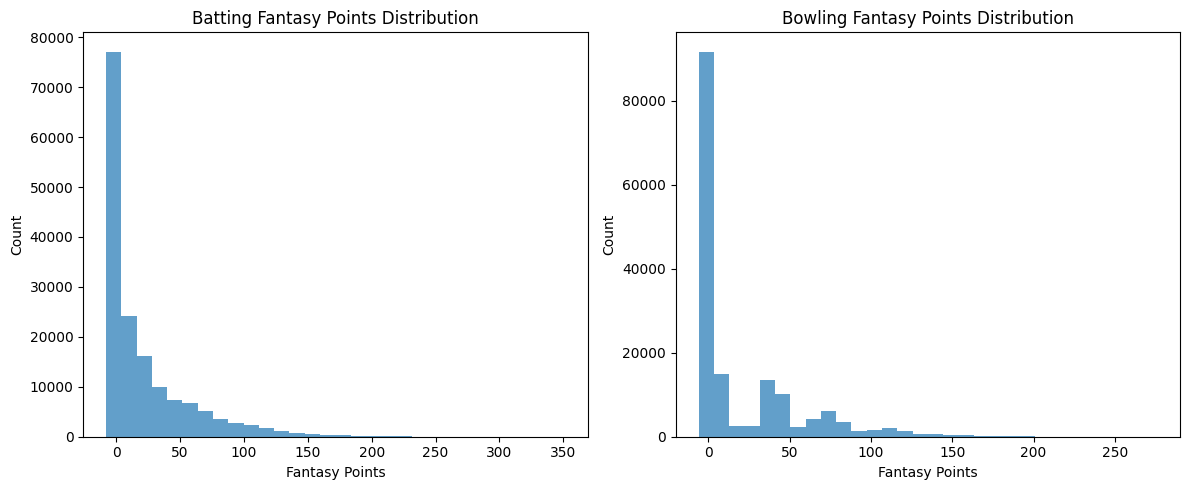

In [5]:
# Merge batting dataframes
# First merge batting features with matchup scores
batting_merged = pd.merge(
    batting_features,
    batting_matchup,
    on=['match_id', 'batter_id'],
    how='left'
)

# Then merge with batting FP
batting_merged = pd.merge(
    batting_merged,
    batting_fp,
    on=['match_id', 'batter_id', 'date'],
    how='left'
)

# Merge bowling dataframes
bowling_merged = pd.merge(
    bowling_features,
    bowling_fp,
    on=['match_id', 'bowler_id', 'date'],
    how='left'
)

print("Batting merged shape:", batting_merged.shape)
print("Bowling merged shape:", bowling_merged.shape)

# Data quality check after merging
print("\nMissing values after merging:")
print(f"Batting merged: {batting_merged.isnull().sum().sum()} missing values")
print(f"Bowling merged: {bowling_merged.isnull().sum().sum()} missing values")

# Simple fillna for numerical columns if any missing values remain
if batting_merged.isnull().sum().sum() > 0:
    for col in batting_merged.select_dtypes(include=['float64', 'int64']).columns:
        if batting_merged[col].isnull().sum() > 0:
            batting_merged[col] = batting_merged[col].fillna(batting_merged[col].mean())

if bowling_merged.isnull().sum().sum() > 0:
    for col in bowling_merged.select_dtypes(include=['float64', 'int64']).columns:
        if bowling_merged[col].isnull().sum() > 0:
            bowling_merged[col] = bowling_merged[col].fillna(bowling_merged[col].mean())

# Display target distributions
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(batting_merged['batting_fp'], bins=30, alpha=0.7)
plt.title('Batting Fantasy Points Distribution')
plt.xlabel('Fantasy Points')
plt.ylabel('Count')

plt.subplot(1, 2, 2)
plt.hist(bowling_merged['bowling_fp'], bins=30, alpha=0.7)
plt.title('Bowling Fantasy Points Distribution')
plt.xlabel('Fantasy Points')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

## 3. Train-Test Split based on Season

In [6]:
# Split batting data
bat_train = batting_merged[batting_merged['season'] < 2023].copy()
bat_test = batting_merged[batting_merged['season'] >= 2023].copy()

# Split bowling data
bowl_train = bowling_merged[bowling_merged['season'] < 2023].copy()
bowl_test = bowling_merged[bowling_merged['season'] >= 2023].copy()

print("Batting train shape:", bat_train.shape)
print("Batting test shape:", bat_test.shape)
print("Bowling train shape:", bowl_train.shape)
print("Bowling test shape:", bowl_test.shape)

# Verify the split
print("\nBatting seasons in train:", bat_train['season'].unique())
print("Batting seasons in test:", bat_test['season'].unique())
print("Bowling seasons in train:", bowl_train['season'].unique())
print("Bowling seasons in test:", bowl_test['season'].unique())

Batting train shape: (124899, 38)
Batting test shape: (35569, 38)
Bowling train shape: (124945, 37)
Bowling test shape: (36096, 37)

Batting seasons in train: [2005 2006 2007 2008 2009 2010 2011 2012 2013 2014 2015 2016 2017 2018
 2019 2020 2021 2022]
Batting seasons in test: [2023 2024 2025]
Bowling seasons in train: [2005 2006 2007 2008 2009 2010 2011 2012 2013 2014 2015 2016 2017 2018
 2019 2020 2021 2022]
Bowling seasons in test: [2023 2024 2025]


## 4. Data Preprocessing

In [7]:
bat_test.date.max()

'2025-03-21'

In [8]:
# Define categorical columns and columns to ignore
categorical_cols = ['bat_team', 'bowl_team', 'venue', 'league']
ignore_cols = ['date', 'match_id', 'batter']

# Create dictionaries to store encodings
encoding_dicts = {}

# Create and fit encoders on all data once
for col in categorical_cols:
    # Get all unique values from both datasets
    all_values = pd.concat([bat_train[col], bat_test[col]]).unique()

    # Create encoder and fit
    encoder = LabelEncoder()
    encoder.fit(all_values)

    # Store mapping in dictionary
    encoding_dicts[col] = dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))

    # Apply encoding using the dictionary
    bat_train[col] = bat_train[col].map(encoding_dicts[col])
    bat_test[col] = bat_test[col].map(encoding_dicts[col])

    # Also apply to bowling data if the column exists
    if col in bowl_train.columns:
        bowl_train[col] = bowl_train[col].map(encoding_dicts[col])
    if col in bowl_test.columns:
        bowl_test[col] = bowl_test[col].map(encoding_dicts[col])

    print(f"Encoded {col} with {len(encoding_dicts[col])} unique values")

# Function to handle new data with consistent encoding
def encode_new_data(df, column, encoding_dict):
    # For any new values not seen during training, assign -1
    return df[column].map(lambda x: encoding_dict.get(x, -1))

Encoded bat_team with 179 unique values
Encoded bowl_team with 179 unique values
Encoded venue with 231 unique values
Encoded league with 16 unique values


In [9]:
# Function to preprocess data
def preprocess_data(df, target_col, numerical_cols=None, scaler=None, verbose=True):
    # If numerical columns are not specified, use all numeric columns
    if numerical_cols is None:
        numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
        if target_col in numerical_cols:
            numerical_cols.remove(target_col)
        id_cols = [col for col in numerical_cols if 'id' in col.lower() or 'match' in col.lower() or 'season' in col.lower()]
        for col in id_cols:
            if col in numerical_cols:
                numerical_cols.remove(col)

    # Extract features and target
    X = df[numerical_cols]
    y = df[target_col]

    # Standardize features
    if scaler is None:
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
    else:
        # Use provided scaler without fitting
        X_scaled = scaler.transform(X)

    if verbose:
        print(f"Selected {len(numerical_cols)} numerical features")
        print(f"Feature matrix shape: {X_scaled.shape}")
        print(f"Target vector shape: {y.values.shape}")

    return X_scaled, y.values, scaler, numerical_cols

# Preprocess batting data
# Select numerical features for batting (excluding non-numeric and identifier columns)
bat_numerical_cols = [
    'career_avg', 'career_rpm', 'career_sr', 'career_bpm', 'career_bfpm',
    'inns_avg', 'inns_rpm', 'inns_sr', 'inns_bpm', 'inns_bfpm',
    'ven_avg', 'ven_rpm', 'ven_sr', 'ven_bpm', 'ven_bfpm',
    'ssn_avg', 'ssn_rpm', 'ssn_sr', 'ssn_bpm', 'ssn_bfpm',
    'last5_avg', 'last5_sr', 'last5_rpm', 'last5_bfpm', 'last5_bpm',
    'batter_matchup_score'
]

print("Processing batting data:")
# For training data - fit and transform
X_bat_train, y_bat_train, bat_scaler, bat_features = preprocess_data(
    bat_train, 'batting_fp', bat_numerical_cols
)

# For test data - only transform using the scaler fit on training data
X_bat_test, y_bat_test, _, _ = preprocess_data(
    bat_test, 'batting_fp', bat_features, scaler=bat_scaler, verbose=False
)

# Preprocess bowling data
# Select numerical features for bowling
bowl_numerical_cols = [
    'career_avg', 'career_eco', 'career_sr', 'career_wpm', 'career_opm',
    'inns_avg', 'inns_eco', 'inns_sr', 'inns_wpm', 'inns_opm',
    'venue_avg', 'venue_eco', 'venue_sr', 'venue_wpm', 'venue_opm',
    'ssn_avg', 'ssn_eco', 'ssn_sr', 'ssn_wpm', 'ssn_opm',
    'last5_avg', 'last5_eco', 'last5_sr', 'last5_wpm', 'last5_opm'
]

print("\nProcessing bowling data:")
# For training data - fit and transform
X_bowl_train, y_bowl_train, bowl_scaler, bowl_features = preprocess_data(
    bowl_train, 'bowling_fp', bowl_numerical_cols
)

# For test data - only transform using the scaler fit on training data
X_bowl_test, y_bowl_test, _, _ = preprocess_data(
    bowl_test, 'bowling_fp', bowl_features, scaler=bowl_scaler, verbose=False
)

Processing batting data:
Selected 26 numerical features
Feature matrix shape: (124899, 26)
Target vector shape: (124899,)

Processing bowling data:
Selected 25 numerical features
Feature matrix shape: (124945, 25)
Target vector shape: (124945,)


## 5. Create PyTorch Datasets and DataLoaders

In [10]:
class CricketDataset(Dataset):
    def __init__(self, features, targets):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.targets = torch.tensor(targets, dtype=torch.float32)
    
    def __len__(self):
        return len(self.features)
    
    def __getitem__(self, idx):
        return self.features[idx], self.targets[idx]

# Create PyTorch datasets
bat_train_dataset = CricketDataset(X_bat_train, y_bat_train)
bat_test_dataset = CricketDataset(X_bat_test, y_bat_test)
bowl_train_dataset = CricketDataset(X_bowl_train, y_bowl_train)
bowl_test_dataset = CricketDataset(X_bowl_test, y_bowl_test)

# Find optimal batch size for RTX 4070 laptop GPU
def find_optimal_batch_size(dataset, model_func, input_dim, start_size=64, max_size=512, step=64):
    print("Finding optimal batch size...")
    for batch_size in range(start_size, max_size+1, step):
        try:
            # Free up memory
            torch.cuda.empty_cache()
            gc.collect()
            
            # Create a small test model
            test_model = model_func(input_dim).to(device)
            
            # Create a sample batch
            sample_loader = DataLoader(dataset, batch_size=batch_size)
            inputs, _ = next(iter(sample_loader))
            inputs = inputs.to(device)
            
            # Test forward pass
            _ = test_model(inputs)
            
            memory_used = torch.cuda.memory_allocated() / 1e9
            print(f"Batch size {batch_size} fits in memory. GPU memory used: {memory_used:.2f} GB")
            
            # Clean up
            del test_model, inputs, sample_loader
            torch.cuda.empty_cache()
            gc.collect()
            
        except RuntimeError as e:
            if "CUDA out of memory" in str(e):
                print(f"Maximum batch size: {batch_size-step}. Error: CUDA out of memory")
                return batch_size-step
            else:
                print(f"Error at batch size {batch_size}: {str(e)}")
                return batch_size-step
    
    print(f"All tested batch sizes fit in memory. Maximum tested: {max_size}")
    return max_size

# Define a simple model creator function for batch size testing
def create_test_model(input_dim):
    return nn.Sequential(
        nn.Linear(input_dim, 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1)
    )

# Comment this out if you want to use a fixed batch size instead of finding the optimal one
# optimal_batch_size = find_optimal_batch_size(bat_train_dataset, create_test_model, X_bat_train.shape[1])

# For RTX 4070 laptop GPU, set batch size to 128 as recommended
batch_size = 128
print(f"Using batch size: {batch_size}")

# Create DataLoaders
bat_train_loader = DataLoader(bat_train_dataset, batch_size=batch_size, shuffle=True, pin_memory=True)
bat_test_loader = DataLoader(bat_test_dataset, batch_size=batch_size, pin_memory=True)
bowl_train_loader = DataLoader(bowl_train_dataset, batch_size=batch_size, shuffle=True, pin_memory=True)
bowl_test_loader = DataLoader(bowl_test_dataset, batch_size=batch_size, pin_memory=True)

Using batch size: 128


## 6. Neural ODE Implementation

In [11]:
class ODEFunc(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(ODEFunc, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),  # Tanh is more stable than ReLU for ODEs
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, input_dim)
        )

        # More conservative initialization
        for m in self.net.modules():
            if isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, mean=0, std=0.01)
                nn.init.zeros_(m.bias)

    def forward(self, t, x):
        # Enhanced stability safeguards
        if torch.isnan(x).any() or torch.isinf(x).any():
            # Replace NaNs and Infs with zeros
            x = torch.where(torch.isnan(x) | torch.isinf(x), torch.zeros_like(x), x)

        # Stronger clipping to prevent extreme values
        x = torch.clamp(x, min=-10.0, max=10.0)

        # Apply dynamics with residual connection for stability
        dx = self.net(x)

        # Scale down derivatives more aggressively
        dx = 0.05 * torch.tanh(dx)  # Smaller scale factor

        return dx

class NeuralODE(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim=1):
        super(NeuralODE, self).__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.output_dim = output_dim
        self.integration_time = torch.tensor([0.0, 1.0]).float()

        # Feature transformation layers
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh()
        )

        # ODE function
        self.ode_func = ODEFunc(hidden_dim, hidden_dim)

        # Output layer
        self.decoder = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.Tanh(),
            nn.Linear(hidden_dim // 2, output_dim)
        )

    def forward(self, x):
        # Transform input to hidden state
        h = self.encoder(x)

        # Move integration time to the correct device
        integration_time = self.integration_time.to(x.device)

        try:
            # Start with a very simple solver
            out = odeint(
                self.ode_func,
                h,
                integration_time,
                method='euler',  # Use the simplest solver first
                options={'step_size': 0.1}
            )
        except Exception as e:
            # If the simple solver fails, try with even smaller steps
            try:
                out = odeint(
                    self.ode_func,
                    h,
                    integration_time,
                    method='euler',
                    options={'step_size': 0.05}
                )
            except:
                # Last resort: use midpoint with very small steps
                out = odeint(
                    self.ode_func,
                    h,
                    integration_time,
                    method='midpoint',
                    options={'step_size': 0.01}
                )

        # Take the value at t=1 (the last element)
        out = out[-1]

        # Transform to output
        pred = self.decoder(out)

        return pred.squeeze(-1)

## 7. Training Function with Progress Bar and Mixed Precision

In [12]:
def train_neural_ode(model, train_loader, test_loader, epochs, lr=5e-4):
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.MSELoss()
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, 'min', patience=20, factor=0.5, verbose=True
    )

    scaler = GradScaler()

    train_losses = []
    test_losses = []
    best_test_loss = float('inf')
    best_model = None

    # For early stopping
    patience = 10
    patience_counter = 0

    for epoch in tqdm(range(epochs), desc="Training Progress"):
        # Training phase
        model.train()
        running_loss = 0.0
        batch_count = 0

        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)

            optimizer.zero_grad()

            # Mixed precision training
            with autocast():
                outputs = model(inputs)
                loss = criterion(outputs, targets)

            # Scale the gradients and optimize
            scaler.scale(loss).backward()

            # Gradient clipping - crucial for Neural ODE stability
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)

            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item()
            batch_count += 1

        train_loss = running_loss / batch_count
        train_losses.append(train_loss)

        # Testing phase
        model.eval()
        running_loss = 0.0
        batch_count = 0

        with torch.no_grad():
            for inputs, targets in test_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                running_loss += loss.item()
                batch_count += 1

        test_loss = running_loss / batch_count
        test_losses.append(test_loss)

        # Save the best model
        if test_loss < best_test_loss:
            best_test_loss = test_loss
            best_model = model.state_dict().copy()
            patience_counter = 0
        else:
            patience_counter += 1

        # Update learning rate
        scheduler.step(test_loss)

        if epoch % 5 == 0 or epoch == epochs-1:
            print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.6f}, Test Loss: {test_loss:.6f}")
        
        # Early stopping
        if patience_counter >= patience:
            print(f"Early stopping triggered after epoch {epoch+1}")
            break
    
    # Load the best model
    model.load_state_dict(best_model)
    
    return model, train_losses, test_losses

## 8. Model Evaluation Function

In [13]:
def evaluate_model(model, test_loader, label=""):
    model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for inputs, targets in tqdm(test_loader, desc=f"Evaluating {label} Model"):
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            all_preds.extend(outputs.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())
    
    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)
    
    # Calculate metrics
    mse = mean_squared_error(all_targets, all_preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(all_targets, all_preds)
    mae = mean_absolute_error(all_targets, all_preds)
    
    print(f"\n{label} Model Evaluation:")
    print(f"MSE: {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"R²: {r2:.4f}")
    
    return all_preds, all_targets, {"mse": mse, "rmse": rmse, "mae": mae, "r2": r2}

## 9. Train Batting Model

In [14]:
# Monitor memory before training
print(f"GPU Memory before batting model training: {torch.cuda.memory_allocated()/1e9:.2f} GB")

# Define batting model
input_dim_bat = X_bat_train.shape[1]
hidden_dim_bat = 64
output_dim_bat = 1

bat_model = NeuralODE(input_dim_bat, hidden_dim_bat, output_dim_bat).to(device)
print(f"Batting model parameters: {sum(p.numel() for p in bat_model.parameters() if p.requires_grad)}")

# Train batting model
epochs_bat = 100
bat_model, bat_train_losses, bat_test_losses = train_neural_ode(
    bat_model, bat_train_loader, bat_test_loader, epochs_bat, lr=1e-3
)

GPU Memory before batting model training: 0.00 GB
Batting model parameters: 16321


D:\ED\braintumor\.venv\Lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(
C:\Users\rajat\AppData\Local\Temp\ipykernel_1360\549918241.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


Training Progress:   0%|          | 0/100 [00:00<?, ?it/s]

C:\Users\rajat\AppData\Local\Temp\ipykernel_1360\549918241.py:31: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 1/100, Train Loss: 1197.355058, Test Loss: 1089.821914
Epoch 6/100, Train Loss: 941.735884, Test Loss: 1031.686820
Epoch 11/100, Train Loss: 939.713763, Test Loss: 1031.471283
Epoch 16/100, Train Loss: 937.910303, Test Loss: 1030.913477
Epoch 21/100, Train Loss: 937.131486, Test Loss: 1030.566488
Epoch 26/100, Train Loss: 936.271674, Test Loss: 1031.400943
Early stopping triggered after epoch 30


## 10. Train Bowling Model

In [15]:
# Clear memory after batting model training
torch.cuda.empty_cache()
gc.collect()
print(f"GPU Memory before bowling model training: {torch.cuda.memory_allocated()/1e9:.2f} GB")

# Define bowling model
input_dim_bowl = X_bowl_train.shape[1]
hidden_dim_bowl = 64
output_dim_bowl = 1

bowl_model = NeuralODE(input_dim_bowl, hidden_dim_bowl, output_dim_bowl).to(device)
print(f"Bowling model parameters: {sum(p.numel() for p in bowl_model.parameters() if p.requires_grad)}")

# Train bowling model
epochs_bowl = 100
bowl_model, bowl_train_losses, bowl_test_losses = train_neural_ode(
    bowl_model, bowl_train_loader, bowl_test_loader, epochs_bowl, lr=1e-3
)

GPU Memory before bowling model training: 0.02 GB
Bowling model parameters: 16257


D:\ED\braintumor\.venv\Lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(
C:\Users\rajat\AppData\Local\Temp\ipykernel_1360\549918241.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


Training Progress:   0%|          | 0/100 [00:00<?, ?it/s]

C:\Users\rajat\AppData\Local\Temp\ipykernel_1360\549918241.py:31: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 1/100, Train Loss: 1090.538263, Test Loss: 893.040765
Epoch 6/100, Train Loss: 809.415726, Test Loss: 836.530614
Epoch 11/100, Train Loss: 808.835678, Test Loss: 840.073800
Epoch 16/100, Train Loss: 807.241914, Test Loss: 836.459833
Early stopping triggered after epoch 17


## 11. Evaluate Models

In [16]:
# Evaluate batting model
bat_preds, bat_targets, bat_metrics = evaluate_model(bat_model, bat_test_loader, "Batting")

# Evaluate bowling model
bowl_preds, bowl_targets, bowl_metrics = evaluate_model(bowl_model, bowl_test_loader, "Bowling")

Evaluating Batting Model:   0%|          | 0/278 [00:00<?, ?it/s]


Batting Model Evaluation:
MSE: 1030.7026
RMSE: 32.1046
MAE: 21.2253
R²: 0.2019


Evaluating Bowling Model:   0%|          | 0/282 [00:00<?, ?it/s]


Bowling Model Evaluation:
MSE: 837.4429
RMSE: 28.9386
MAE: 17.9063
R²: 0.3174


## 12. Visualize Results

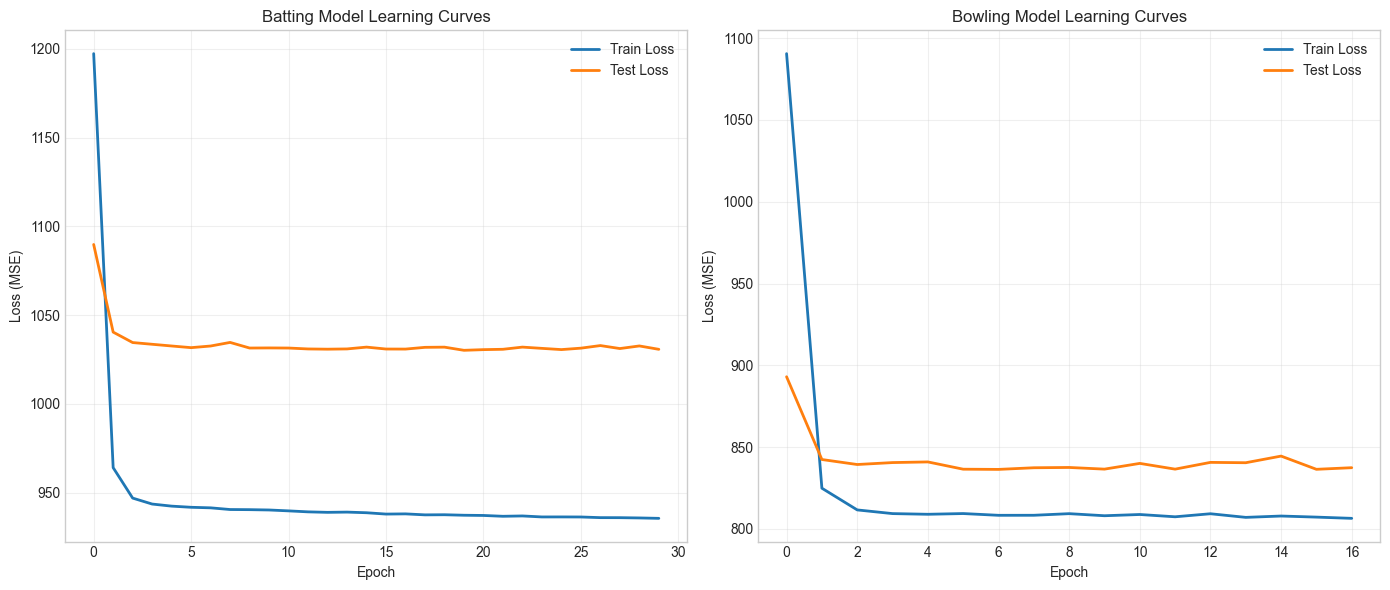

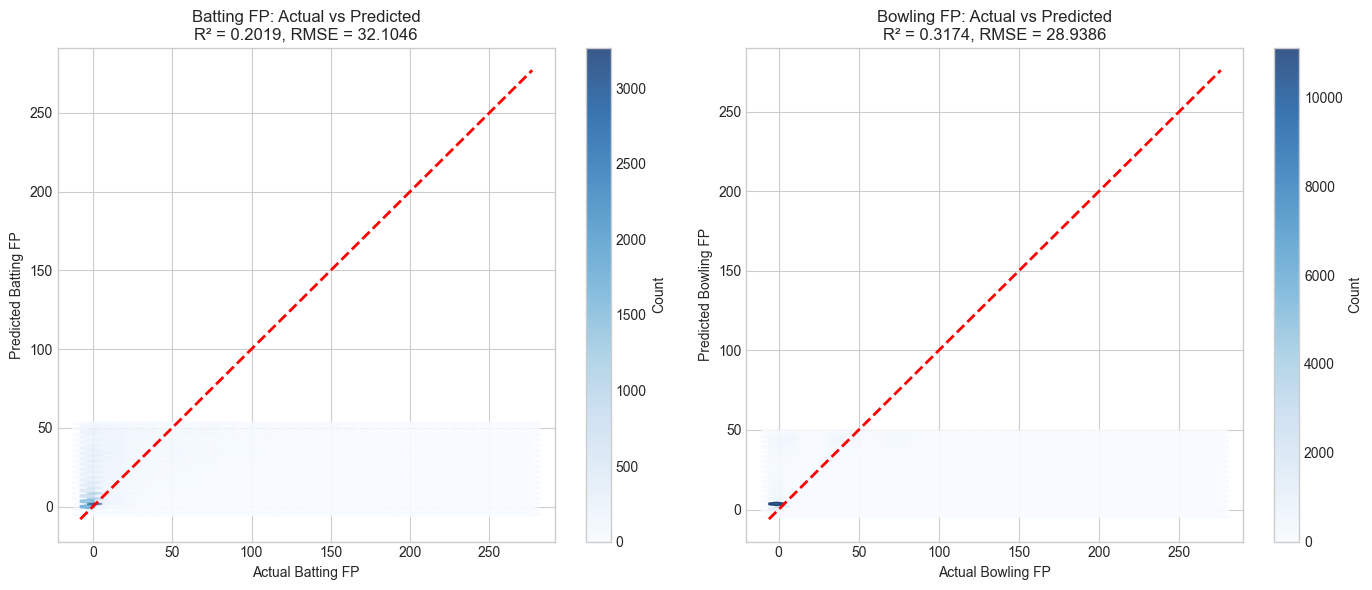

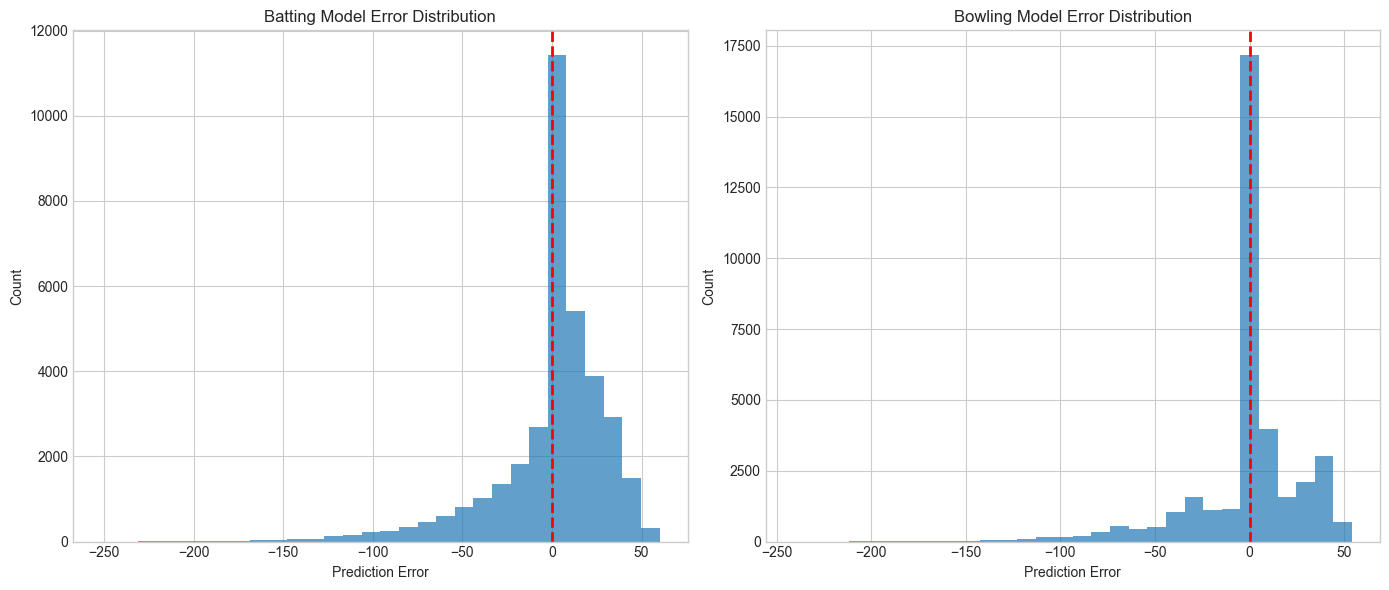

In [17]:
# Set a clean style for plots
plt.style.use('seaborn-v0_8-whitegrid')

# Plot training and testing losses for batting model
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.plot(bat_train_losses, label='Train Loss', color='#1f77b4', linewidth=2)
plt.plot(bat_test_losses, label='Test Loss', color='#ff7f0e', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Batting Model Learning Curves')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot training and testing losses for bowling model
plt.subplot(1, 2, 2)
plt.plot(bowl_train_losses, label='Train Loss', color='#1f77b4', linewidth=2)
plt.plot(bowl_test_losses, label='Test Loss', color='#ff7f0e', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Bowling Model Learning Curves')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot predicted vs actual values for batting model
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)

# Create hexbin plot for dense areas
plt.hexbin(bat_targets, bat_preds, gridsize=30, cmap='Blues', alpha=0.8)
plt.colorbar(label='Count')

# Add identity line
min_val = min(min(bat_targets), min(bat_preds))
max_val = max(max(bat_targets), max(bat_preds))
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2)

plt.xlabel('Actual Batting FP')
plt.ylabel('Predicted Batting FP')
plt.title(f'Batting FP: Actual vs Predicted\nR² = {bat_metrics["r2"]:.4f}, RMSE = {bat_metrics["rmse"]:.4f}')

# Plot predicted vs actual values for bowling model
plt.subplot(1, 2, 2)

# Create hexbin plot for dense areas
plt.hexbin(bowl_targets, bowl_preds, gridsize=30, cmap='Blues', alpha=0.8)
plt.colorbar(label='Count')

# Add identity line
min_val = min(min(bowl_targets), min(bowl_preds))
max_val = max(max(bowl_targets), max(bowl_preds))
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2)

plt.xlabel('Actual Bowling FP')
plt.ylabel('Predicted Bowling FP')
plt.title(f'Bowling FP: Actual vs Predicted\nR² = {bowl_metrics["r2"]:.4f}, RMSE = {bowl_metrics["rmse"]:.4f}')
plt.tight_layout()
plt.show()

# Plot error distributions
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
errors_bat = bat_preds - bat_targets
plt.hist(errors_bat, bins=30, alpha=0.7, color='#1f77b4')
plt.axvline(x=0, color='r', linestyle='--', linewidth=2)
plt.xlabel('Prediction Error')
plt.ylabel('Count')
plt.title('Batting Model Error Distribution')

plt.subplot(1, 2, 2)
errors_bowl = bowl_preds - bowl_targets
plt.hist(errors_bowl, bins=30, alpha=0.7, color='#1f77b4')
plt.axvline(x=0, color='r', linestyle='--', linewidth=2)
plt.xlabel('Prediction Error')
plt.ylabel('Count')
plt.title('Bowling Model Error Distribution')
plt.tight_layout()
plt.show()

## 13. Feature Importance Analysis

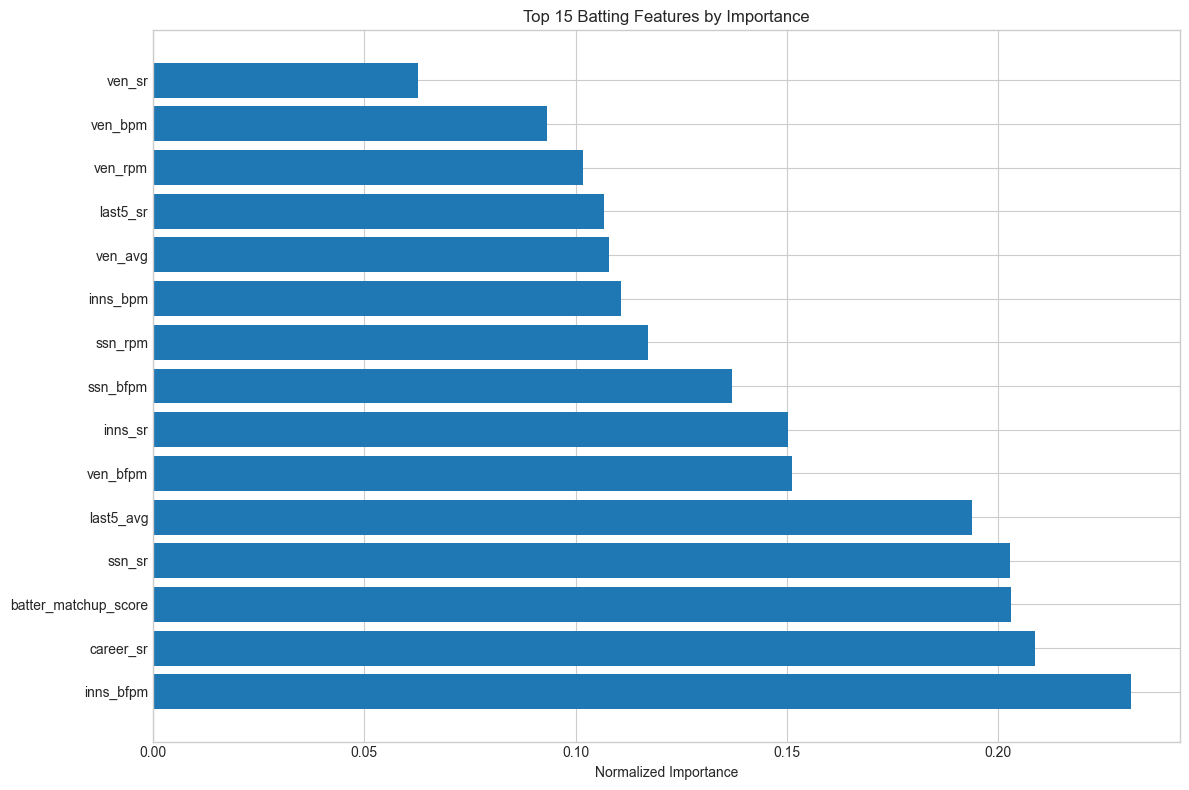

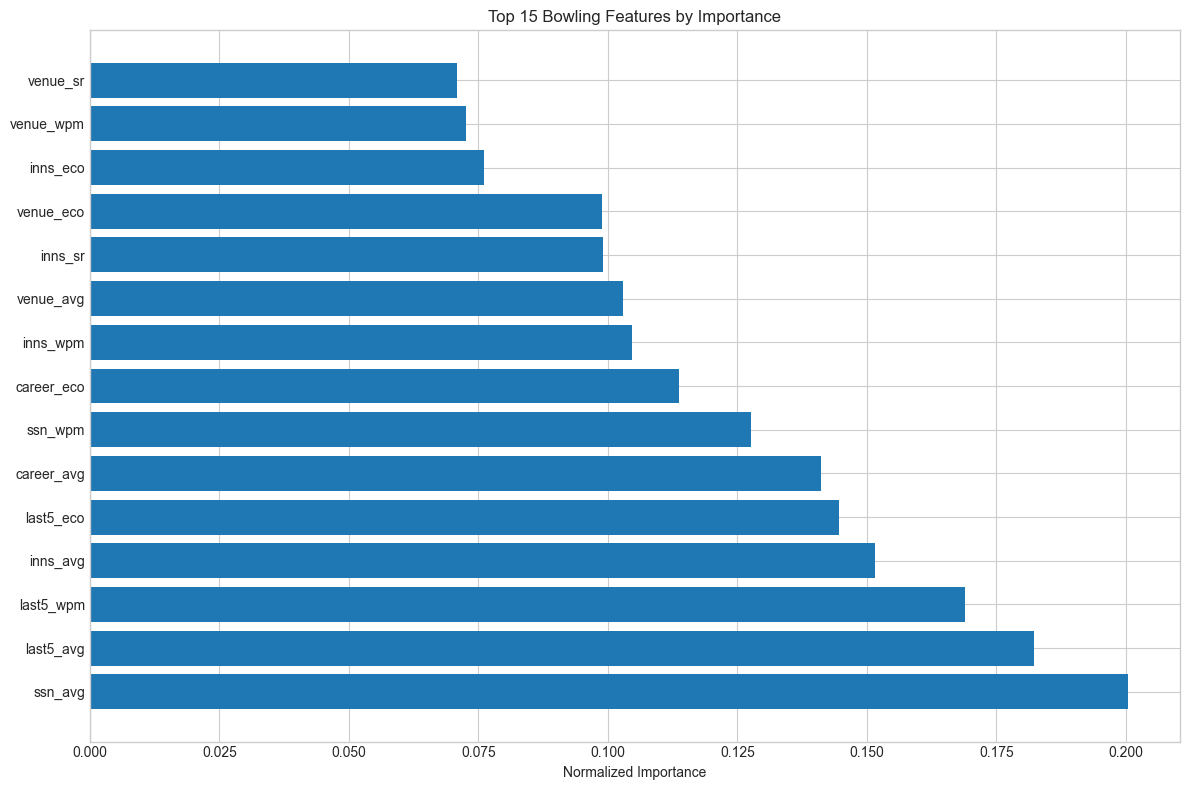

In [18]:
def analyze_feature_importance(model, features_list, test_loader, n_samples=1000):
    """Analyze feature importance by measuring the impact of perturbing each feature"""
    model.eval()
    feature_importances = {}

    # Get a sample batch
    sample_inputs = []
    sample_targets = []

    # Collect samples
    with torch.no_grad():
        for inputs, targets in test_loader:
            sample_inputs.append(inputs)
            sample_targets.append(targets)
            if len(torch.cat(sample_inputs)) >= n_samples:
                break

    # Combine samples and limit to n_samples
    sample_inputs = torch.cat(sample_inputs)[:n_samples].to(device)

    # Get baseline predictions - ADD torch.no_grad() CONTEXT HERE
    with torch.no_grad():
        baseline_preds = model(sample_inputs).cpu().detach().numpy()

    # For each feature, measure impact of perturbation
    for i, feature_name in enumerate(features_list):
        # Create a perturbed version
        perturbed = sample_inputs.clone()
        perturbed[:, i] = torch.mean(perturbed[:, i])  # Replace with mean value

        # Get predictions with perturbed feature - ADD torch.no_grad() CONTEXT HERE
        with torch.no_grad():
            perturbed_preds = model(perturbed).cpu().detach().numpy()

        # Calculate impact of perturbation (mean absolute difference)
        impact = np.mean(np.abs(perturbed_preds - baseline_preds))
        feature_importances[feature_name] = impact

    # Normalize importances
    max_importance = max(feature_importances.values())
    normalized_importances = {k: v/max_importance for k, v in feature_importances.items()}

    # Sort by importance
    sorted_importances = dict(sorted(normalized_importances.items(), key=lambda x: x[1], reverse=True))

    return sorted_importances
# Analyze batting features
bat_importances = analyze_feature_importance(bat_model, bat_features, bat_test_loader)

# Plot batting feature importances
plt.figure(figsize=(12, 8))
plt.barh(list(bat_importances.keys())[-15:], list(bat_importances.values())[-15:], color='#1f77b4')
plt.xlabel('Normalized Importance')
plt.title('Top 15 Batting Features by Importance')
plt.tight_layout()
plt.show()

# Analyze bowling features
bowl_importances = analyze_feature_importance(bowl_model, bowl_features, bowl_test_loader)

# Plot bowling feature importances
plt.figure(figsize=(12, 8))
plt.barh(list(bowl_importances.keys())[-15:], list(bowl_importances.values())[-15:], color='#1f77b4')
plt.xlabel('Normalized Importance')
plt.title('Top 15 Bowling Features by Importance')
plt.tight_layout()
plt.show()

## 14. Save Models

In [20]:
# Create a directory for your models
save_dir = "./cricket_models"  # Change this to any path you want
os.makedirs(save_dir, exist_ok=True)  # Create the directory if it doesn't exist

# Define file paths by joining directory and filenames
bat_model_path = os.path.join(save_dir, r"D:\ED\statModel\Neural_ode\batting_neural_ode_model.pth")
bowl_model_path = os.path.join(save_dir, r"D:\ED\statModel\Neural_ode\bowling_neural_ode_model.pth")

# Save the batting model
torch.save({
    'model_state_dict': bat_model.state_dict(),
    'input_dim': input_dim_bat,
    'hidden_dim': hidden_dim_bat,
    'output_dim': output_dim_bat,
    'features': bat_features,
    'scaler': bat_scaler,
    'encoding_dicts': encoding_dicts,  # Add this line
    'metrics': bat_metrics,
    'feature_importance': bat_importances,
    'timestamp': time.strftime('%Y-%m-%d-%H-%M-%S')
}, bat_model_path)

# Save the bowling model with the same change
torch.save({
    'model_state_dict': bowl_model.state_dict(),
    'input_dim': input_dim_bowl,
    'hidden_dim': hidden_dim_bowl,
    'output_dim': output_dim_bowl,
    'features': bowl_features,
    'scaler': bowl_scaler,
    'encoding_dicts': encoding_dicts,  # Add this line
    'metrics': bowl_metrics,
    'feature_importance': bowl_importances,
    'timestamp': time.strftime('%Y-%m-%d-%H-%M-%S')
}, bowl_model_path)

print(f"Models saved to {save_dir}")

Models saved to ./cricket_models


## 15. Load and Inference

In [ ]:
def load_model_and_predict(model_path, input_data):
    # Load model and metadata
    checkpoint = torch.load(model_path)
    input_dim = checkpoint['input_dim']
    hidden_dim = checkpoint['hidden_dim']
    output_dim = checkpoint['output_dim']
    features = checkpoint['features']
    scaler = checkpoint['scaler']
    
    # Create model
    model = NeuralODE(input_dim, hidden_dim, output_dim).to(device)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()
    
    # Preprocess input data
    input_features = input_data[features]
    scaled_input = scaler.transform(input_features)
    input_tensor = torch.tensor(scaled_input, dtype=torch.float32).to(device)
    
    # Make prediction
    with torch.no_grad():
        prediction = model(input_tensor)
    
    return prediction.cpu().numpy()

# Example usage (assuming you have new data)
# new_bat_data = pd.DataFrame(...)
# new_bowl_data = pd.DataFrame(...)
# bat_predictions = load_model_and_predict('batting_neural_ode_model.pth', new_bat_data)
# bowl_predictions = load_model_and_predict('bowling_neural_ode_model.pth', new_bowl_data)

In [ ]:
# Prediction example using test data
# Let's take a small sample from the test set
sample_size = 5

# Get sample batting data
sample_bat_indices = np.random.choice(len(bat_test), sample_size, replace=False)
sample_bat_data = bat_test.iloc[sample_bat_indices].copy()

# Predict using our model
sample_bat_preds = load_model_and_predict('batting_neural_ode_model.pth', sample_bat_data)

# Display results
result_bat_df = pd.DataFrame({
    'Player': sample_bat_data['batter'],
    'Match ID': sample_bat_data['match_id'],
    'Actual FP': sample_bat_data['batting_fp'],
    'Predicted FP': sample_bat_preds,
    'Error': sample_bat_preds - sample_bat_data['batting_fp']
})

print("Batting Predictions Sample:")
display(result_bat_df)

# Get sample bowling data
sample_bowl_indices = np.random.choice(len(bowl_test), sample_size, replace=False)
sample_bowl_data = bowl_test.iloc[sample_bowl_indices].copy()

# Predict using our model
sample_bowl_preds = load_model_and_predict('bowling_neural_ode_model.pth', sample_bowl_data)

# Display results
result_bowl_df = pd.DataFrame({
    'Player': sample_bowl_data['bowler'],
    'Match ID': sample_bowl_data['match_id'],
    'Actual FP': sample_bowl_data['bowling_fp'],
    'Predicted FP': sample_bowl_preds,
    'Error': sample_bowl_preds - sample_bowl_data['bowling_fp']
})

print("\nBowling Predictions Sample:")
display(result_bowl_df)